# Econ 4850 · Economic Analysis with Python
## Lecture 3c: Gradient Descent (Bonus)
Geoffrey Kam, Washington University in St. Louis · g.kam@wustl.edu · Spring 2025

**What you'll learn**

- The idea behind gradient descent and the role of the learning rate.
- How to compute gradients with automatic differentiation using `autograd`.
- How to estimate OLS by gradient descent and by mini-batch gradient descent, and why this is useful even though OLS has a closed form.

In [1]:
import autograd.numpy as np  # autograd's version of NumPy, so that functions can be differentiated
from autograd import grad
from matplotlib import pyplot as plt

## Introduction

- Gradient descent is an iterative optimization algorithm that finds a local minimum of a differentiable function.

- In simpler terms, suppose you have a function (often a *loss* or *cost* function in machine learning) that depends on some parameters. Gradient descent is a strategy for adjusting these parameters to reduce the function's value gradually, ending up at (or near) its minimum.

- It is arguably the most commonly used optimization algorithm, and it is one of the reasons why automatic differentiation is so popular.

## The Core Idea

Suppose you have a function $f(\theta)$ that depends on some parameters $\theta$ (which could be scalars, vectors, or matrices). The goal is to find $\theta^*$ that minimizes $f(\theta)$.

- The **gradient** of $f(\theta)$, denoted $\nabla f(\theta)$, is the vector of partial derivatives of $f$ with respect to each parameter in $\theta$.
- The gradient points "uphill" (in the direction of steepest increase) in the parameter space.
- To move "downhill," we update the parameters in the *opposite* direction of the gradient.

The *iterative update* rule for gradient descent is

$$
\theta_{\text{new}} = \theta_{\text{old}} - \alpha \nabla f(\theta_{\text{old}}),
$$

where $\alpha$ is the **learning rate**, a positive number that controls the size of each step.

### Visualizing it

- This [YouTube video](https://youtu.be/qg4PchTECck?si=fa6_PC5Q1no6LmQs&t=82) shows how gradient descent works.

- Since the objective may not be smooth, we may need to tune the learning rate so that the (local or global) minimum can be reached. The step can also incorporate momentum. Common choices are:
    1. a fixed learning rate,
    2. learning-rate decay (deals with spikes), and
    3. adaptive learning rates (balance speed and stability).

## Why Is Gradient Descent Important?

1. **Broad applicability**
   - Gradient descent is the workhorse for training models in machine learning, including linear regression, logistic regression, neural networks, and more.
   - It is not limited to machine learning: it shows up in optimization problems across mathematics, statistics, and economics.

2. **Efficiency**
   - When the function you are minimizing is complex or high-dimensional, closed-form solutions can be impractical.
   - Gradient descent is a straightforward iterative method that scales relatively well to large problems.

3. **Simplicity and flexibility**
   - You can implement gradient descent in just a few lines of code.
   - Variants such as **stochastic gradient descent (SGD)**, **mini-batch gradient descent**, and **momentum** methods improve convergence on large datasets.
      - Stochastic and mini-batch gradient descent are more common in practice. They differ in how the data used to compute each gradient are selected.
      - Common practice in machine learning is to do each step less precisely but very efficiently.
      - The randomness can actually improve out-of-sample fit.
      - These topics are beyond the scope of this course.

## Recall: Automatic Differentiation

- There are several ways to compute a derivative.

- The state-of-the-art way is automatic differentiation (AD).
    - AD is not numerical differentiation, which takes a finite difference.

- We used AD once before, with `autograd`.

- How AD works is beyond the scope of this course. If you are interested, watch [this video](https://www.youtube.com/watch?v=wG_nF1awSSY&t=641s).

In [2]:
def f(x):
    return np.abs(x)

In [3]:
f_prime = grad(f)

In [4]:
x_grid = np.linspace(-5, 5, 100)

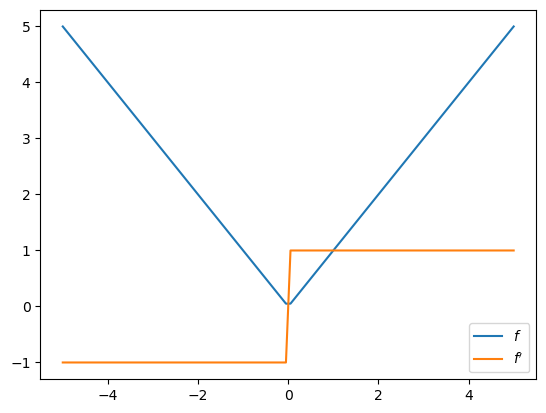

In [5]:
fig, ax = plt.subplots()
ax.plot(x_grid, [f(x) for x in x_grid], label="$f$")
ax.plot(x_grid, [f_prime(x) for x in x_grid], label="$f'$")
ax.legend()
plt.show()

### Handling multiple inputs

By default, `grad` differentiates with respect to the first argument, which here is the vector `x`.

In [6]:
f_multi = lambda x, y: np.abs(x[0]) + np.power(x[1], 2) + y
f_multi_prime = grad(f_multi)
x = np.array([2.0, 2.0])
f_multi_prime(x, 10)

array([1., 4.])

## Example: Solving OLS with Gradient Descent

- Recall that OLS minimizes the **sum of squared errors (SSE)**:
$$SSE = \sum_{i=1}^n (y_i - \hat{y}_i)^2.$$

- The code below minimizes the mean squared error $MSE = SSE/n$, which has the same minimizer. With $\hat y_i = m x_i + b$, its gradient is
$$\frac{\partial MSE}{\partial m} = \frac{2}{n}\sum_{i=1}^n (\hat y_i - y_i)\,x_i, \qquad \frac{\partial MSE}{\partial b} = \frac{2}{n}\sum_{i=1}^n (\hat y_i - y_i).$$

- Let's practice gradient descent with OLS, starting with this analytical derivative.

In [7]:
# 1. Generate some sample data with a linear relationship y = 4 + 3x,
#    plus some noise for demonstration.
np.random.seed(850)  # for reproducibility

sample_size = 1000
n_iterations = 1000

X = 2 * np.random.rand(sample_size, 1)

y = 4 + 3 * X + np.random.randn(sample_size, 1)

Converged after 328 iterations
Final parameters:
m = 3.1413, b = 3.9079


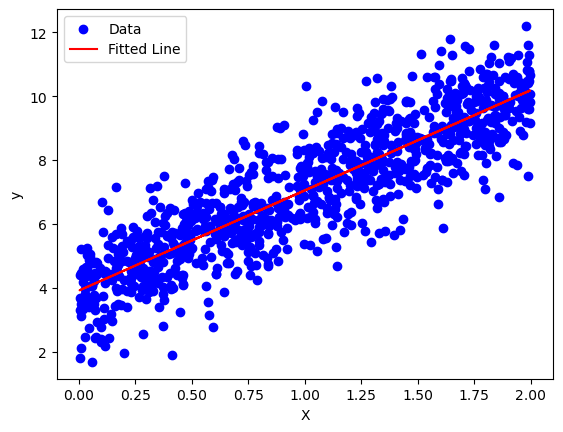

In [8]:
# 2. Initialize the parameters (slope m and intercept b)
m = 0.0
b = 0.0

# 3. Define the hyperparameters
learning_rate = 0.1

N = len(X)  # number of data points

# 4. Gradient descent
for i in range(n_iterations):
    # Current predictions
    y_pred = m * X + b

    # Compute the gradients
    dm = (2 / N) * np.sum((y_pred - y) * X)
    db = (2 / N) * np.sum(y_pred - y)

    # Update the parameters
    m -= learning_rate * dm
    b -= learning_rate * db

    # Stop when the step is small
    if learning_rate * np.sqrt(np.sum(dm**2 + db**2)) < 1e-6:
        print(f"Converged after {i} iterations")
        break

# Print the learned parameters
print(f"Final parameters:\nm = {m:.4f}, b = {b:.4f}")

# 5. Plot the data and the fitted line
plt.scatter(X, y, color='blue', label='Data')
plt.plot(X, m * X + b, color='red', label='Fitted Line')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.show()

**Exercise:** Use automatic differentiation instead.

In [9]:
# Add a column of ones to X for the intercept
X_b = np.hstack((np.ones((sample_size, 1)), X))


# Define the OLS loss function
def ols_loss(theta, X, y):
    """Compute the mean squared error (MSE) for OLS."""
    predictions = X @ theta
    errors = y - predictions
    return np.mean(errors**2)


# Initialize the parameters
theta = np.zeros((X_b.shape[1], 1))  # start with zero weights
learning_rate = 0.1
n_iterations = 1000
tolerance = 1e-6  # stopping criterion


def gd(theta, X_b, y, learning_rate, n_iterations, tolerance):
    loss = lambda theta: ols_loss(theta, X_b, y)
    gradient = grad(loss)
    for iteration in range(n_iterations):
        gradients = gradient(theta)  # compute the gradient with autograd
        theta_new = theta - learning_rate * gradients  # update the parameters

        # Stopping criterion: stop if the change in parameters is below the tolerance
        if np.linalg.norm(theta_new - theta, ord=2) < tolerance:
            print(f"Converged at iteration {iteration}")
            break
        theta = theta_new
    return theta


theta = gd(theta, X_b, y, learning_rate, n_iterations, tolerance)

# Print the final parameters
print(f"Estimated parameters:\nIntercept (b0): {theta[0][0]:.4f}, Slope (b1): {theta[1][0]:.4f}")

# Compare with the closed-form solution
theta_closed_form = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
print(f"Closed-form solution:\nIntercept (b0): {theta_closed_form[0][0]:.4f}, Slope (b1): {theta_closed_form[1][0]:.4f}")

Converged at iteration 328
Estimated parameters:
Intercept (b0): 3.9079, Slope (b1): 3.1413
Closed-form solution:
Intercept (b0): 3.9080, Slope (b1): 3.1413


### Mini-batch gradient descent

Mini-batch gradient descent (MBGD) computes each gradient on a small random subset (a mini-batch) of the data. Each pass through the shuffled data is called an epoch.

In [10]:
# Gradient of the loss function with respect to its first argument, theta
gradient = grad(ols_loss, argnum=0)

# Initialize the parameters
batch_size = 20  # mini-batch size
theta = np.zeros((X_b.shape[1], 1))


def mb_gd(theta, X_b, y, learning_rate, batch_size, n_iterations, tolerance):
    # Each iteration is one epoch
    for iteration in range(n_iterations):
        # Shuffle the data at the start of each epoch
        shuffled_indices = np.random.permutation(sample_size)
        X_b_shuffled = X_b[shuffled_indices]
        y_shuffled = y[shuffled_indices]

        for i in range(0, sample_size, batch_size):
            # Create the mini-batch
            X_batch = X_b_shuffled[i:i + batch_size]
            y_batch = y_shuffled[i:i + batch_size]

            # Compute the gradient on the mini-batch
            gradients = gradient(theta, X_batch, y_batch)

            # Update the parameters
            theta_new = theta - learning_rate * gradients

            # Stopping criterion: stop if the change in parameters is below the tolerance
            if np.linalg.norm(theta_new - theta, ord=2) < tolerance:
                print(f"Converged at iteration {iteration}, batch {i // batch_size}")
                return theta_new

            theta = theta_new

    return theta_new


theta = mb_gd(theta, X_b, y, learning_rate, batch_size, n_iterations, tolerance)

# Print the final parameters
print(f"Estimated parameters:\nIntercept (b0): {theta[0][0]:.4f}, Slope (b1): {theta[1][0]:.4f}")

# Compare with the closed-form solution
theta_closed_form = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
print(f"Closed-form solution:\nIntercept (b0): {theta_closed_form[0][0]:.4f}, Slope (b1): {theta_closed_form[1][0]:.4f}")

Estimated parameters:
Intercept (b0): 3.9110, Slope (b1): 3.1385
Closed-form solution:
Intercept (b0): 3.9080, Slope (b1): 3.1413


## Why Learn to Solve OLS with Gradient Descent When There Is a Closed-Form Solution?

1. **Scalability with large datasets**
    - The closed-form solution for OLS requires inverting the matrix $X^\top X$.
    - When the number of features is very large, or the data are high-dimensional, this matrix inversion can become computationally expensive or even infeasible because of memory constraints.
    - Gradient descent updates the parameters iteratively and avoids direct matrix inversion, so it can handle larger datasets more efficiently.

2. **Numerical stability and practical considerations**
    - Even when a closed-form solution is available, numerical issues such as multicollinearity or near-singularity of $X^\top X$ can make the closed-form approach unstable.
    - Gradient descent, with proper regularization and learning-rate adjustments, can offer a more robust alternative under such conditions.